# Crop Recommendation Based on Soil and Climate Conditions
**YEEAP Capstone – Module 5: Building and Evaluating the AI Solution**
FUSE AI-201 – AI Model Development and Implementation · **Group 6** · Domain: Agriculture

This notebook follows the eight Module 5 tasks in order:
`Problem → Data → Analysis → Model → Evaluation → Testing → Working Prototype`

| # | Task | Section |
|---|------|---------|
| 1 | Refine the problem | Task 1 |
| 2 | Define the AI solution | Task 2 |
| 3 | Prepare the data | Task 3 |
| 4 | Explore the data | Task 4 |
| 5 | Build a baseline model | Task 5 |
| 6 | Improve the model | Task 6 |
| 7 | Evaluate the model | Task 7 |
| 8 | Test the solution | Task 8 |

**Group members** (from the Module 4 proposal): Henok Afework Birhanu, Daniel Alemayehu Belachew, Zinashwork Belay, Misgana Belete Songaye, Nigist Tesfu Berhane, Eden Beyene, Binyam, Shumye Birara Getu, Tsegaye Teka Bireda, Tadele Tsedalu Birhane.
Individual contributions are listed in `README.md` and the report (to be completed by the group with only the members who actually participated).

**How to run:** `pip install -r requirements.txt`, then *Run All*. The notebook needs `data/Crop_recommendation.csv` and the helper module `recommender.py` in the same folder. All random seeds are fixed (`42`), so results are reproducible.

---
## Task 1 – Refine the Problem

**Problem statement (confirmed from Module 4).** Given a plot's soil nutrient levels (Nitrogen, Phosphorus, Potassium), soil pH, and local climate conditions (temperature, humidity, rainfall), recommend the single most suitable crop to plant from a defined set of 22 candidate crops.

| Element | Definition |
|---|---|
| **Target users** | Smallholder / individual farmers (end users); agricultural extension officers (validate and discuss recommendations); cooperatives / NGOs (distribute the tool). The tool supports, and does not replace, human judgment. |
| **Inputs** | 7 numeric values: `N`, `P`, `K` (soil nutrient ratios), `ph`, `temperature` (°C), `humidity` (%), `rainfall` (mm) |
| **Output** | Top recommended crop **plus the next two best alternatives with confidence scores** |
| **ML task** | Multi-class classification, 22 classes |

**Objectives / success criteria (from Module 4, Section 6)**

| Criterion | Target |
|---|---|
| Macro F1-score (primary) | ≥ 0.90 on the held-out test set |
| Overall accuracy | ≥ 0.90 |
| Per-class recall | no crop below 0.80 |
| Top-3 accuracy | ≥ 98 % |
| Baseline comparison | final model must beat the KNN / Decision-Tree baseline on macro F1 |
| Latency | single-plot recommendation well under 1 second |

**Changes from the Module 4 proposal.** No change of domain, task, dataset, features or metrics. Two small, documented adjustments:
1. *Data source:* the CSV used here is an identical copy of the Kaggle *Crop Recommendation Dataset* obtained from a public GitHub mirror (the "equivalent public mirror" fallback described in proposal Section 3). The schema, size (2,200 rows) and class balance (22 × 100) are verified in Task 3. The group can swap in the Kaggle file at any time.
2. *Final-model choice is decided by the data* (Task 6) rather than fixed in advance. The proposal named Random Forest as primary and SVM / Naive Bayes as fallbacks; the notebook compares all of them and reports which one was selected and why.

---
## Task 2 – Define the AI Solution

**Approach.** Supervised multi-class classification using tabular machine learning (scikit-learn). Each candidate is wrapped in a `Pipeline` so that preprocessing (scaling, optional feature engineering) is learned **only from training data** and is saved together with the model.

**How the solution works**

```
7 plot readings ──► validation (range / type checks) ──► Pipeline [ (ratio features) → (scaler) → classifier ]
                                                              │
                                        class probabilities for 22 crops ──► top-3 crops + confidence + warnings
```

**Why this approach**
- All inputs are numeric and measurable *before* planting, and the label is categorical → classification is the natural framing (not regression).
- The dataset is small (2,200 rows), so lightweight models train in seconds on a laptop – no GPU needed.
- **Random Forest** (primary, as proposed): handles features on different scales without scaling, resists over-fitting better than a single tree, and gives feature-importance information that can be explained to farmers and extension officers.
- **Baselines:** K-Nearest Neighbors (with scaling) and a default Decision Tree.
- **Alternatives / fallback:** SVM (RBF kernel) and Gaussian Naive Bayes.
- Probabilities are needed for the "top-3 with confidence" output, so every candidate must support `predict_proba` (SVM probabilities are obtained through calibration).

**Model-selection rule (fixed before the final test evaluation).** Models are compared on the **validation** set by macro F1. Because the validation set has only 330 rows (one sample ≈ 0.3 percentage points), models within **0.005** macro F1 of the best are treated as tied; among tied models the one with the best 5-fold cross-validation macro F1 on the training set is chosen. The **test set is used only once**, to confirm the chosen model.

---
## Task 3 – Prepare the Data
### 3.0 Setup

In [1]:
import warnings, json, time, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, joblib

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     RandomizedSearchCV, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (f1_score, accuracy_score, recall_score, classification_report,
                             confusion_matrix, top_k_accuracy_score)
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import f_classif

from recommender import (FEATURES, HARD_LIMITS, add_ratio_features, recommend,
                         load_model, validate_input)

warnings.filterwarnings("ignore", category=FutureWarning)
RS = 42
np.random.seed(RS)
sns.set_theme(style="whitegrid", context="notebook")
for d in ("figures", "models", "outputs"):
    Path(d).mkdir(exist_ok=True)

print("python", platform.python_version(), "| scikit-learn", sklearn.__version__,
      "| pandas", pd.__version__)

python 3.13.16 | scikit-learn 1.9.1 | pandas 3.0.5


### 3.1 Load and inspect the dataset

In [2]:
df = pd.read_csv("data/Crop_recommendation.csv")
print("Shape:", df.shape)
display(df.head())
print(df.dtypes.to_string())

# Verify the file matches the Module 4 proposal (2,200 rows, 7 numeric features, 22 crops x 100)
assert list(df.columns) == FEATURES + ["label"], "Unexpected columns"
assert df.shape == (2200, 8), "Unexpected number of rows"
assert df["label"].nunique() == 22 and df["label"].value_counts().nunique() == 1

print("\nMissing values :", int(df.isna().sum().sum()))
print("Duplicate rows :", int(df.duplicated().sum()))
print("Classes        :", df["label"].nunique(), "| rows per class:", int(df["label"].value_counts().iloc[0]))
print("\nSchema and balance match the Module 4 proposal.")

Shape: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label              str

Missing values : 0
Duplicate rows : 0
Classes        : 22 | rows per class: 100

Schema and balance match the Module 4 proposal.


**Data cleaning decisions**
- *Missing values / duplicates:* none found, so nothing to impute or drop (the check above would show otherwise).
- *Encoding:* all seven features are numeric, so no categorical feature encoding is needed. The target is a string crop name; scikit-learn classifiers encode string labels internally, and the saved model returns crop names directly.
- *Scaling:* applied **inside pipelines** (fit on training data only) for distance/kernel models (KNN, SVM). Tree-based models and Naive Bayes do not need it.
- *Outliers:* inspected below. Whether to remove them is decided by an experiment in Task 6, not by assumption.

In [3]:
# Outlier inspection with the IQR rule (1.5 x IQR) – inspected here, decision tested in Task 6
q1, q3 = df[FEATURES].quantile(0.25), df[FEATURES].quantile(0.75)
iqr = q3 - q1
flag = (df[FEATURES] < q1 - 1.5 * iqr) | (df[FEATURES] > q3 + 1.5 * iqr)

rows = []
for f in FEATURES:
    crops = df.loc[flag[f], "label"].value_counts()
    rows.append({"feature": f, "n_flagged": int(flag[f].sum()),
                 "share_%": round(100 * flag[f].mean(), 1),
                 "crops holding the flagged values": ", ".join(f"{c} ({n})" for c, n in crops.head(4).items())})
display(pd.DataFrame(rows))
print(f"Rows with at least one flagged value: {int(flag.any(axis=1).sum())} "
      f"({100*flag.any(axis=1).mean():.1f}% of the data)")

,feature,n_flagged,share_%,crops holding the flagged values
0,N,0,0.0,
1,P,138,6.3,"apple (70), grapes (68)"
2,K,200,9.1,"grapes (100), apple (100)"
3,temperature,86,3.9,"papaya (35), grapes (34), orange (17)"
4,humidity,30,1.4,chickpea (30)
5,ph,57,2.6,"mothbeans (42), chickpea (13), mango (2)"
6,rainfall,100,4.5,"rice (68), papaya (17), coconut (15)"


Rows with at least one flagged value: 432 (19.6% of the data)


### 3.2 Stratified train / validation / test split (70 / 15 / 15)

In [4]:
X, y = df[FEATURES], df["label"]
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RS)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RS)

print(f"train {len(X_train)} | validation {len(X_val)} | test {len(X_test)}")
print("Rows per crop  train:", y_train.value_counts().unique(),
      "| val:", y_val.value_counts().unique(), "| test:", y_test.value_counts().unique())
assert not (set(X_train.index) & set(X_val.index)) and not (set(X_train.index) & set(X_test.index)) \
       and not (set(X_val.index) & set(X_test.index)), "Leakage between splits!"
print("No row appears in more than one split.")

train 1540 | validation 330 | test 330
Rows per crop  train: [70] | val: [15] | test: [15]
No row appears in more than one split.


---
## Task 4 – Explore the Data
All exploration uses the **training split only**, so nothing about the validation or test rows influences our decisions.

,count,mean,std,min,25%,50%,75%,max
N,1540.0,50.46,37.03,0.00,21.00,37.00,84.00,140.00
P,1540.0,53.29,32.84,5.00,28.00,51.00,68.00,145.00
K,1540.0,48.13,50.72,5.00,20.00,32.00,48.00,205.00
temperature,1540.0,25.58,5.13,8.83,22.75,25.50,28.48,43.36
humidity,1540.0,71.44,22.29,14.26,60.16,80.55,89.87,99.98
ph,1540.0,6.47,0.78,3.50,5.96,6.43,6.93,9.94
rainfall,1540.0,103.35,54.97,20.21,64.70,94.72,123.61,298.56


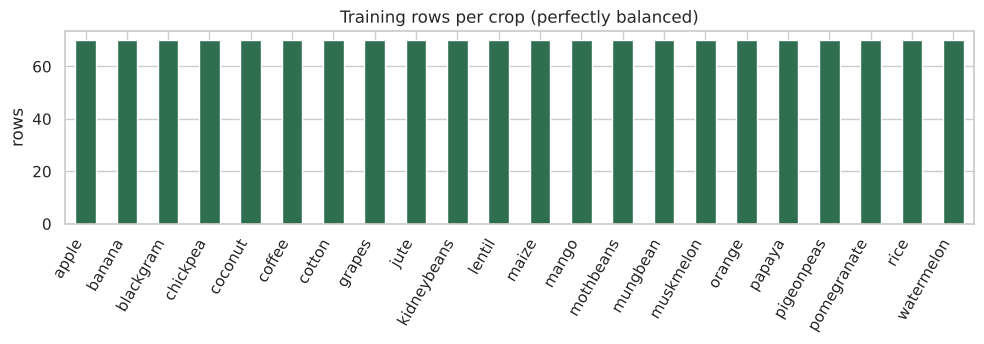

In [5]:
train = X_train.assign(label=y_train)
display(train[FEATURES].describe().T.round(2))

fig, ax = plt.subplots(figsize=(10, 3.6))
train["label"].value_counts().sort_index().plot.bar(ax=ax, color="#2f6f4f")
ax.set(title="Training rows per crop (perfectly balanced)", ylabel="rows", xlabel="")
plt.xticks(rotation=60, ha="right"); plt.tight_layout()
plt.savefig("figures/01_class_balance.png", dpi=150); plt.show()

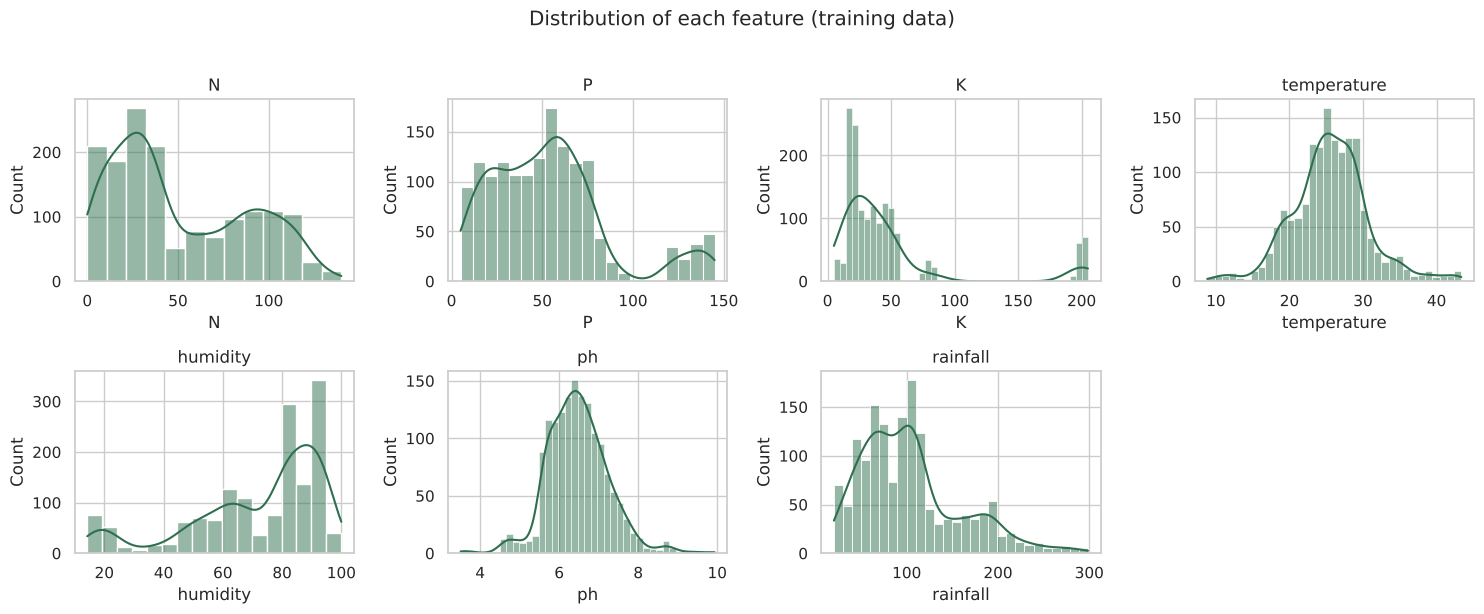

In [6]:
# Feature distributions
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, f in zip(axes.ravel(), FEATURES):
    sns.histplot(train[f], kde=True, ax=ax, color="#2f6f4f")
    ax.set_title(f)
axes.ravel()[-1].axis("off")
plt.suptitle("Distribution of each feature (training data)", y=1.02)
plt.tight_layout(); plt.savefig("figures/02_distributions.png", dpi=150, bbox_inches="tight"); plt.show()

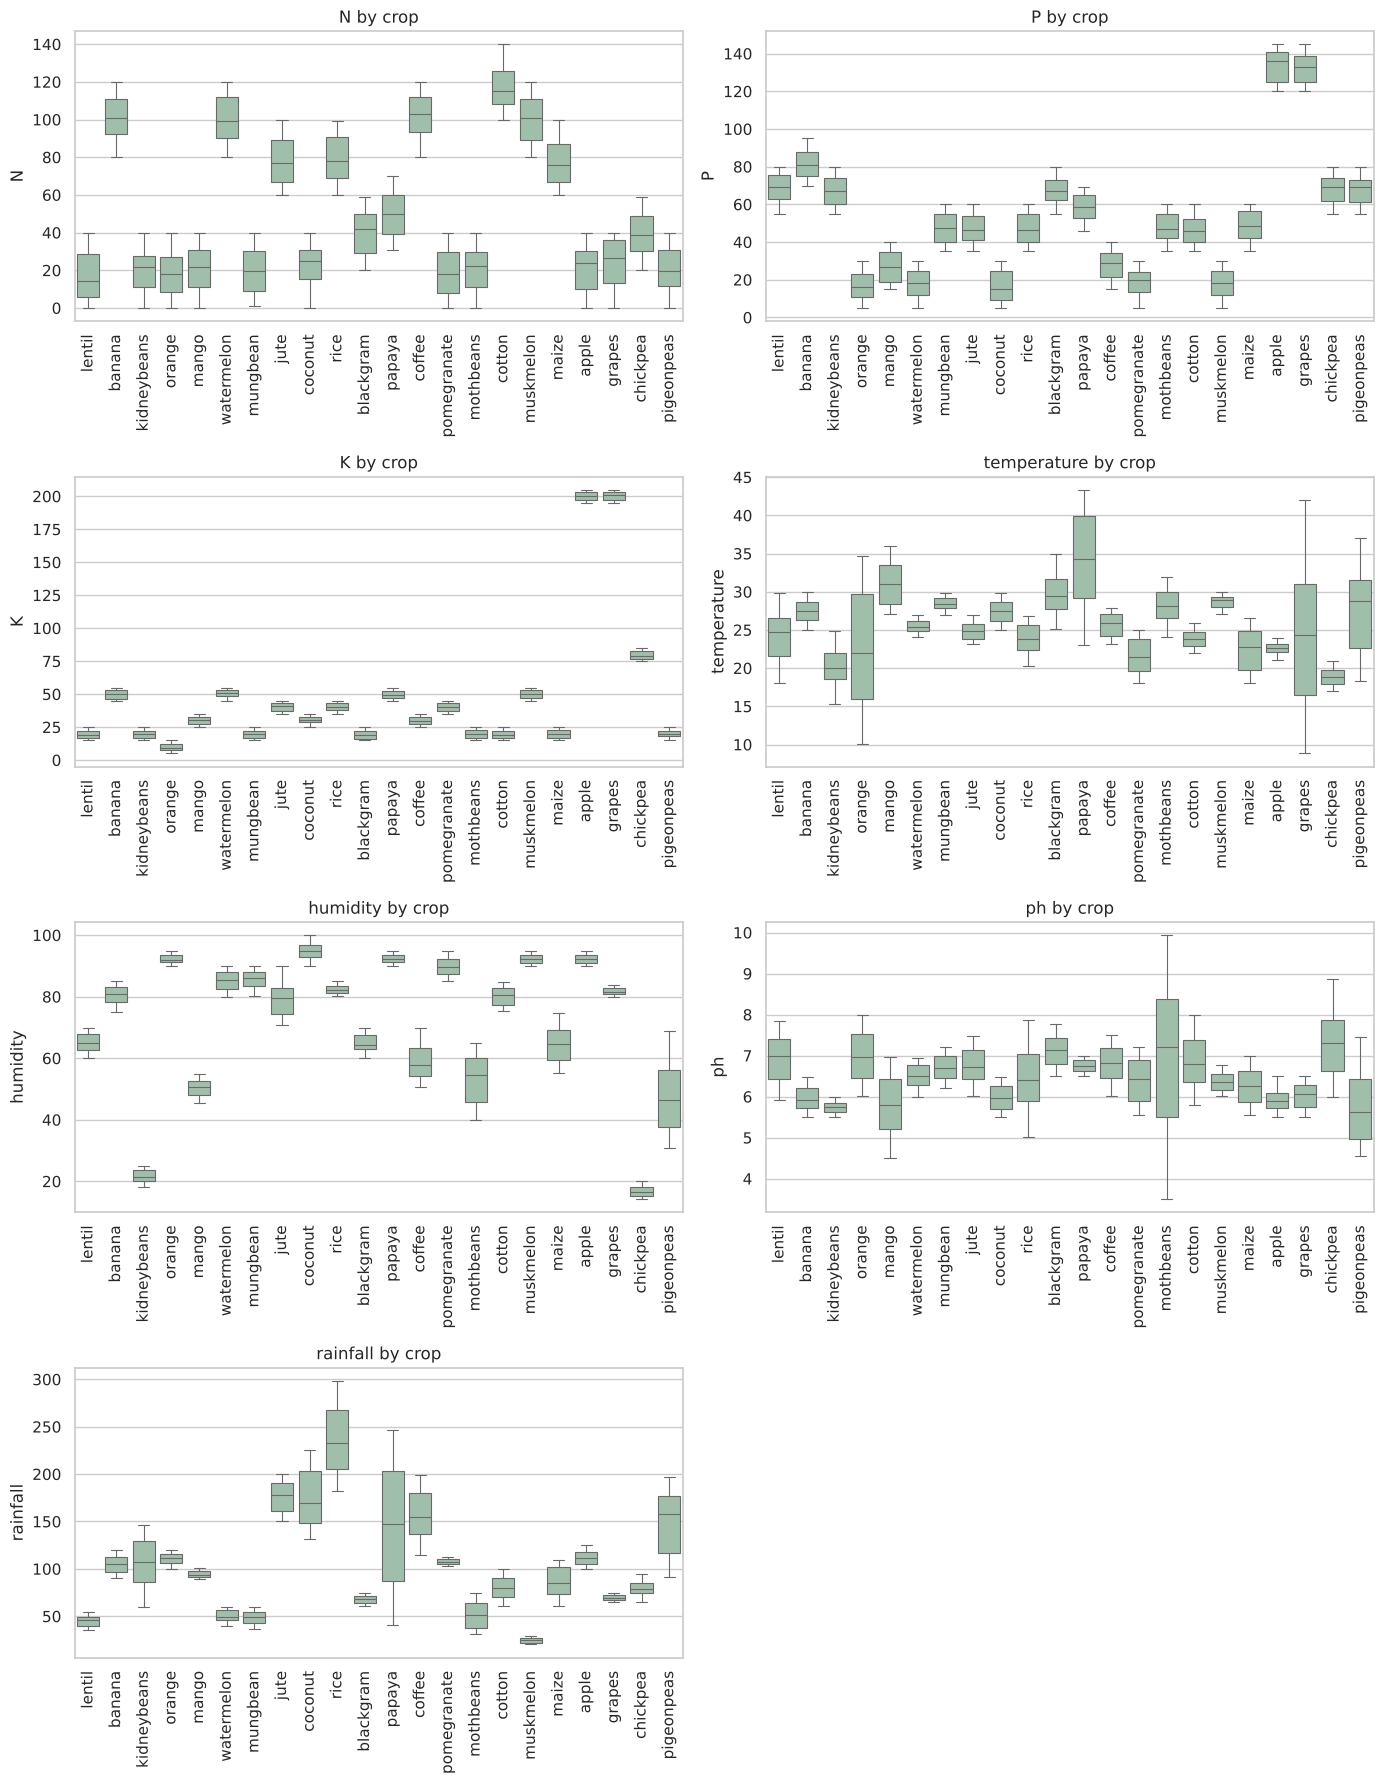

In [7]:
# How each feature varies across crops
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
for ax, f in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=train, x="label", y=f, ax=ax, color="#9bc4a8", fliersize=2, linewidth=0.8)
    ax.set_title(f"{f} by crop"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=90)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.savefig("figures/03_boxplots_by_crop.png", dpi=130); plt.show()

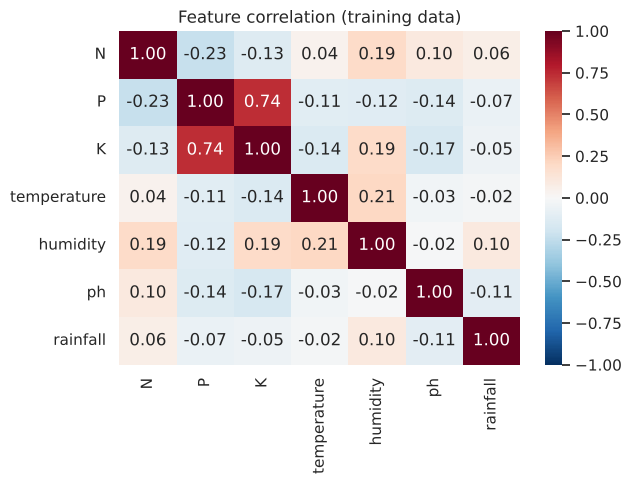

Strongest feature pairs:


,level_0,level_1,corr
9,P,K,0.74
1,N,P,-0.23
25,temperature,humidity,0.21


In [8]:
# Correlation between features
corr = train[FEATURES].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Feature correlation (training data)")
plt.tight_layout(); plt.savefig("figures/04_correlation.png", dpi=150); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
             .rename("corr").reset_index().assign(abs_corr=lambda d: d["corr"].abs())
             .sort_values("abs_corr", ascending=False))
print("Strongest feature pairs:")
display(pairs.head(3)[["level_0", "level_1", "corr"]].round(2))

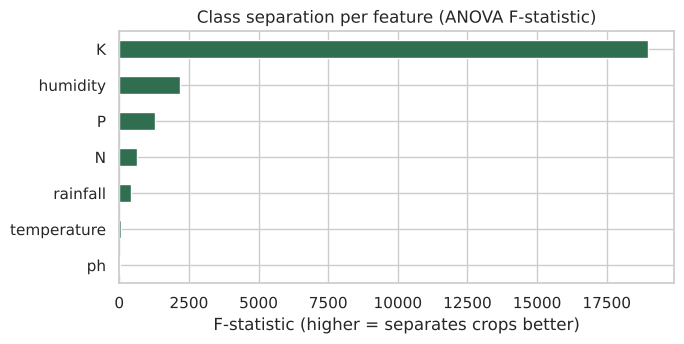

Ranking: K > humidity > P > N > rainfall > temperature > ph
Proposal expected rainfall, humidity and potassium to be strong differentiators.
Top 3 here: ['K', 'humidity', 'P']


In [9]:
# Which features separate the crops best? (one-way ANOVA F-statistic on the training data)
F_vals, _ = f_classif(X_train, y_train)
sep = pd.Series(F_vals, index=FEATURES).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 3.6))
sep.sort_values().plot.barh(ax=ax, color="#2f6f4f")
ax.set(title="Class separation per feature (ANOVA F-statistic)", xlabel="F-statistic (higher = separates crops better)")
plt.tight_layout(); plt.savefig("figures/05_feature_separation.png", dpi=150); plt.show()
print("Ranking:", " > ".join(sep.index))
print("Proposal expected rainfall, humidity and potassium to be strong differentiators.")
print("Top 3 here:", list(sep.index[:3]))

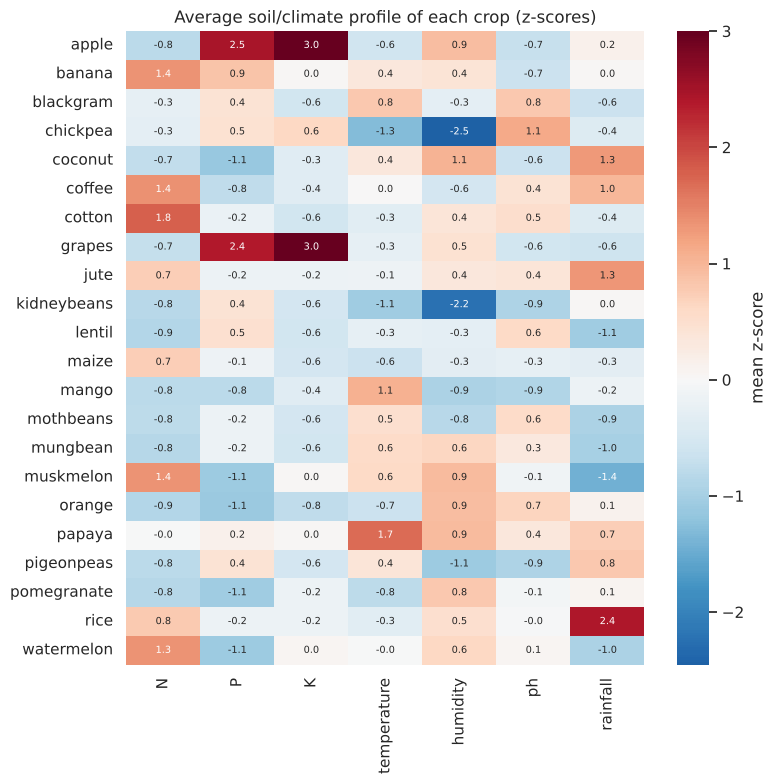

Crop pairs with the most similar average profiles (smaller distance = more similar):
  muskmelon    vs watermelon   distance 0.86
  apple        vs grapes       distance 0.97
  orange       vs pomegranate  distance 0.97
  blackgram    vs mothbeans    distance 1.07
  lentil       vs mothbeans    distance 1.13
  jute         vs rice         distance 1.21


In [10]:
# Crop "profiles": mean z-scored feature values per crop, and which crops look most alike
mu, sd = X_train.mean(), X_train.std()
profile = ((X_train - mu) / sd).groupby(y_train).mean()
fig, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(profile, cmap="RdBu_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax,
            cbar_kws={"label": "mean z-score"})
ax.set_title("Average soil/climate profile of each crop (z-scores)"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("figures/06_crop_profiles.png", dpi=150); plt.show()

# Pairs of crops whose average profiles are closest -> most likely to be confused by any model
from itertools import combinations
dist = {(a, b): float(np.linalg.norm(profile.loc[a] - profile.loc[b])) for a, b in combinations(profile.index, 2)}
closest = sorted(dist.items(), key=lambda kv: kv[1])[:6]
print("Crop pairs with the most similar average profiles (smaller distance = more similar):")
for (a, b), d in closest:
    print(f"  {a:12s} vs {b:12s} distance {d:.2f}")

### What the exploration tells us (and what it means for the model)
The numbers printed above drive these conclusions:
- **Data quality is high:** no missing values or duplicates, and the classes are perfectly balanced, so accuracy is not distorted by class imbalance and no re-sampling is needed. The balance is a property of the *benchmark*, not of real farming, where some crops are planted far more often than others.
- **Outliers are crop-specific, not errors:** the flagged values sit mostly with particular crops (see the outlier table in Task 3 – e.g. very high rainfall or potassium belong to a few crops). They carry real signal, so we test rather than assume whether removing them helps (Task 6).
- **Crops occupy distinct regions of feature space:** the boxplots and profile heatmap show crops differ strongly in climate (rainfall, humidity, temperature) and some nutrients. This explains why even simple models score well.
- **Feature relationships:** the correlation matrix shows which features move together (the strongest pair is printed above). Strongly correlated features add little independent information but are not harmful for tree models.
- **Where errors are likely:** crops with similar average profiles (closest pairs printed above) are the ones a model is most likely to confuse, so we check the confusion matrix for exactly these pairs in Task 7.
- **Implication:** high accuracy is expected on this clean benchmark. That says little about performance on noisy real-world farm data, which is why Task 7 also stresses the model with measurement noise and Task 8 with edge cases.

---
## Task 5 – Build a Baseline Model
Two simple, default-setting baselines as planned in the proposal: **K-Nearest Neighbors** (scaled, because it is distance-based) and a **Decision Tree**. They are scored on the **validation** set.

In [11]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

def make_pipe(clf, scale=True, ratios=False):
    steps = []
    if ratios:
        steps.append(("ratios", FunctionTransformer(add_ratio_features)))
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("clf", clf))
    return Pipeline(steps)

def evaluate(model, X_, y_):
    pred, proba, labels = model.predict(X_), model.predict_proba(X_), model.classes_
    rec = recall_score(y_, pred, labels=labels, average=None, zero_division=0)
    return {"macro_f1": f1_score(y_, pred, average="macro"),
            "accuracy": accuracy_score(y_, pred),
            "min_class_recall": rec.min(), "worst_class": str(labels[rec.argmin()]),
            "top3_accuracy": top_k_accuracy_score(y_, proba, k=3, labels=labels)}

fitted, val_rows = {}, {}

def fit_eval(name, pipe, already_fitted=False):
    if not already_fitted:
        pipe.fit(X_train, y_train)
    fitted[name] = pipe
    m = evaluate(pipe, X_val, y_val)
    cv = cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="f1_macro", n_jobs=-1)
    m.update(cv_macro_f1=cv.mean(), cv_std=cv.std())
    val_rows[name] = m
    return m

fit_eval("KNN (baseline)", make_pipe(KNeighborsClassifier(), scale=True))
fit_eval("Decision Tree (baseline)", make_pipe(DecisionTreeClassifier(random_state=RS), scale=False))

base = pd.DataFrame.from_dict({k: val_rows[k] for k in ["KNN (baseline)", "Decision Tree (baseline)"]}, orient="index")
display(base.round(4))

baseline_name = base["macro_f1"].idxmax()
print(f"Reference baseline = {baseline_name}  (validation macro F1 = {base.loc[baseline_name, 'macro_f1']:.4f})")

# Why scaling matters for distance-based models (illustration)
knn_unscaled = make_pipe(KNeighborsClassifier(), scale=False).fit(X_train, y_train)
print(f"KNN WITHOUT scaling, validation macro F1 = {evaluate(knn_unscaled, X_val, y_val)['macro_f1']:.4f}")

,macro_f1,accuracy,min_class_recall,worst_class,top3_accuracy,cv_macro_f1,cv_std
KNN (baseline),0.9848,0.9848,0.8667,rice,1.0000,0.9640,0.0088
Decision Tree (baseline),0.9755,0.9758,0.8000,mothbeans,0.9788,0.9837,0.0109


Reference baseline = KNN (baseline)  (validation macro F1 = 0.9848)
KNN WITHOUT scaling, validation macro F1 = 0.9726


---
## Task 6 – Improve the Model
Improvements tested, each compared against the baseline on the **same validation set**:
1. Different algorithms: Random Forest, SVM, Gaussian Naive Bayes
2. Feature engineering: N:P, N:K, P:K ratios (suggested in the proposal)
3. Hyper-parameter tuning (Random Forest, SVM) using 5-fold cross-validation on the **training** data only
4. Outlier handling experiment (remove IQR outliers from the training data or keep them)

In [12]:
# 1) Algorithms with default settings
fit_eval("Random Forest (default)", make_pipe(RandomForestClassifier(random_state=RS), scale=False))
fit_eval("SVM (default, calibrated)", make_pipe(CalibratedClassifierCV(SVC(random_state=RS), ensemble=False), scale=True))
fit_eval("Gaussian Naive Bayes", make_pipe(GaussianNB(), scale=False))

# 2) Feature engineering – decided on cross-validation of the training data (not on validation)
fit_eval("Random Forest + NPK ratios", make_pipe(RandomForestClassifier(random_state=RS), scale=False, ratios=True))
cv_plain = val_rows["Random Forest (default)"]["cv_macro_f1"]
cv_ratio = val_rows["Random Forest + NPK ratios"]["cv_macro_f1"]
use_ratios = cv_ratio > cv_plain + 0.002
print(f"RF 5-fold CV macro F1: plain {cv_plain:.4f} vs with ratios {cv_ratio:.4f} -> "
      f"{'ratios kept' if use_ratios else 'ratios NOT kept (no clear gain)'} for tuning")

RF 5-fold CV macro F1: plain 0.9954 vs with ratios 0.9935 -> ratios NOT kept (no clear gain) for tuning


In [13]:
# 3) Hyper-parameter tuning (cross-validated on training data only)
rf_search = RandomizedSearchCV(
    make_pipe(RandomForestClassifier(random_state=RS), scale=False, ratios=use_ratios),
    param_distributions={"clf__n_estimators": [100, 200, 300, 500],
                         "clf__max_depth": [None, 10, 20, 30],
                         "clf__min_samples_split": [2, 5, 10],
                         "clf__min_samples_leaf": [1, 2, 4],
                         "clf__max_features": ["sqrt", "log2", None]},
    n_iter=25, cv=cv5, scoring="f1_macro", n_jobs=-1, random_state=RS)
rf_search.fit(X_train, y_train)
print("Best RF params:", rf_search.best_params_)
fit_eval("Random Forest (tuned)", rf_search.best_estimator_, already_fitted=True)

svm_search = GridSearchCV(
    make_pipe(CalibratedClassifierCV(SVC(random_state=RS), ensemble=False), scale=True),
    param_grid={"clf__estimator__C": [1, 10, 100], "clf__estimator__gamma": ["scale", 0.05, 0.2]},
    cv=cv5, scoring="f1_macro", n_jobs=-1)
svm_search.fit(X_train, y_train)
print("Best SVM params:", svm_search.best_params_)
fit_eval("SVM (tuned, calibrated)", svm_search.best_estimator_, already_fitted=True)

Best RF params: {'clf__n_estimators': 500, 'clf__min_samples_split': 10, 'clf__min_samples_leaf': 2, 'clf__max_features': 'log2', 'clf__max_depth': 20}


Best SVM params: {'clf__estimator__C': 100, 'clf__estimator__gamma': 0.2}


{'macro_f1': 0.9878517316017316,
 'accuracy': 0.9878787878787879,
 'min_class_recall': np.float64(0.8666666666666667),
 'worst_class': 'rice',
 'top3_accuracy': 1.0,
 'cv_macro_f1': np.float64(0.9843344441987378),
 'cv_std': np.float64(0.008179861122548801)}

In [14]:
# 4) Outlier experiment: does removing IQR outliers from the TRAINING data help?
lo = X_train.quantile(0.25) - 1.5 * (X_train.quantile(0.75) - X_train.quantile(0.25))
hi = X_train.quantile(0.75) + 1.5 * (X_train.quantile(0.75) - X_train.quantile(0.25))
is_out = ((X_train < lo) | (X_train > hi)).any(axis=1)
rf_noout = make_pipe(RandomForestClassifier(random_state=RS), scale=False).fit(X_train[~is_out], y_train[~is_out])
all_labels = sorted(y_train.unique())
a = f1_score(y_val, fitted["Random Forest (default)"].predict(X_val), average="macro", labels=all_labels, zero_division=0)
b = f1_score(y_val, rf_noout.predict(X_val), average="macro", labels=all_labels, zero_division=0)
vanished = sorted(set(all_labels) - set(y_train[~is_out]))
left = y_train[~is_out].value_counts()
print(f"Training rows flagged as outliers: {int(is_out.sum())} of {len(X_train)} ({100*is_out.mean():.1f}%)")
print(f"Crops that would lose ALL their training rows if outliers were removed: {vanished if vanished else 'none'}")
print(f"Fewest training rows left for any remaining crop: {int(left.min())} (originally 70)")
print(f"RF validation macro F1 (all 22 crops) - keep outliers: {a:.4f} | remove outliers: {b:.4f}")
print("Decision:", "keep outliers (removal does not help)" if b <= a + 0.002 else "removal helps")

Training rows flagged as outliers: 304 of 1540 (19.7%)
Crops that would lose ALL their training rows if outliers were removed: ['apple', 'grapes']
Fewest training rows left for any remaining crop: 22 (originally 70)
RF validation macro F1 (all 22 crops) - keep outliers: 0.9909 | remove outliers: 0.8752
Decision: keep outliers (removal does not help)


### Model comparison and selection (validation set)

,macro_f1,accuracy,min_class_recall,worst_class,top3_accuracy,cv_macro_f1,cv_std
Gaussian Naive Bayes,0.9939,0.9939,0.9333,lentil,1.0000,0.9948,0.0039
Random Forest + NPK ratios,0.9939,0.9939,0.9333,blackgram,1.0000,0.9935,0.0046
Random Forest (default),0.9909,0.9909,0.9333,blackgram,1.0000,0.9954,0.0033
Random Forest (tuned),0.9909,0.9909,0.9333,blackgram,1.0000,0.9941,0.0038
"SVM (default, calibrated)",0.9909,0.9909,0.8667,rice,1.0000,0.9749,0.0100
"SVM (tuned, calibrated)",0.9879,0.9879,0.8667,rice,1.0000,0.9843,0.0082
KNN (baseline),0.9848,0.9848,0.8667,rice,1.0000,0.9640,0.0088
Decision Tree (baseline),0.9755,0.9758,0.8000,mothbeans,0.9788,0.9837,0.0109


Candidates tied within 0.005 of the best validation macro F1: ['Gaussian Naive Bayes', 'Random Forest + NPK ratios', 'Random Forest (default)', 'Random Forest (tuned)', 'SVM (default, calibrated)']
SELECTED FINAL MODEL: Random Forest (default)


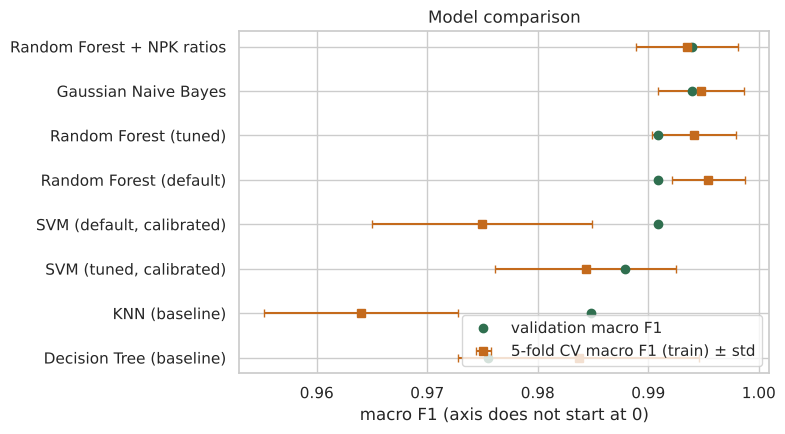

In [15]:
results = pd.DataFrame.from_dict(val_rows, orient="index")
results = results.sort_values(["macro_f1", "cv_macro_f1"], ascending=False)
display(results.round(4))

# Selection rule: within 0.005 macro F1 of the best = tied; among tied choose best CV macro F1
non_baseline = results.drop(index=["KNN (baseline)", "Decision Tree (baseline)"])
best_val = non_baseline["macro_f1"].max()
tied = non_baseline[non_baseline["macro_f1"] >= best_val - 0.005]
final_name = tied["cv_macro_f1"].idxmax()
print("Candidates tied within 0.005 of the best validation macro F1:", list(tied.index))
print("SELECTED FINAL MODEL:", final_name)
if "Random Forest" not in final_name:
    print("NOTE: this differs from the proposal's primary model (Random Forest). The proposal named "
          "SVM / Naive Bayes as fallbacks, and the choice is documented in the report.")

fig, ax = plt.subplots(figsize=(8, 4.5))
order = results.sort_values("macro_f1").index
ax.errorbar(results.loc[order, "macro_f1"], range(len(order)), fmt="o", color="#2f6f4f", label="validation macro F1")
ax.errorbar(results.loc[order, "cv_macro_f1"], range(len(order)), xerr=results.loc[order, "cv_std"],
            fmt="s", color="#c46a1c", capsize=3, label="5-fold CV macro F1 (train) ± std")
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set(xlabel="macro F1 (axis does not start at 0)", title="Model comparison")
ax.legend(loc="lower right"); plt.tight_layout()
plt.savefig("figures/07_model_comparison.png", dpi=150); plt.show()

---
## Task 7 – Evaluate the Model
The selected model is now evaluated on the **held-out test set** (touched only here) with the metrics defined in the proposal: macro F1, accuracy, per-class precision/recall, top-3 accuracy, confusion matrix and latency. The baseline is scored on the same test rows.

In [16]:
final = fitted[final_name]
test_m = evaluate(final, X_test, y_test)
base_m = evaluate(fitted[baseline_name], X_test, y_test)

summary = pd.DataFrame({"Final: " + final_name: test_m, "Baseline: " + baseline_name: base_m}).T
display(summary.round(4))

pred = final.predict(X_test)
proba = final.predict_proba(X_test)
report = classification_report(y_test, pred, output_dict=True, zero_division=0)
display(pd.DataFrame(report).T.round(3).iloc[:-3].sort_values("recall"))

,macro_f1,accuracy,min_class_recall,worst_class,top3_accuracy
Final: Random Forest (default),0.996966,0.99697,0.933333,rice,1.0
Baseline: KNN (baseline),0.9724,0.972727,0.8,orange,0.99697


,precision,recall,f1-score,support
rice,1.000,0.933,0.966,15.0
apple,1.000,1.000,1.000,15.0
blackgram,1.000,1.000,1.000,15.0
banana,1.000,1.000,1.000,15.0
coconut,1.000,1.000,1.000,15.0
coffee,1.000,1.000,1.000,15.0
cotton,1.000,1.000,1.000,15.0
chickpea,1.000,1.000,1.000,15.0
jute,0.938,1.000,0.968,15.0
kidneybeans,1.000,1.000,1.000,15.0


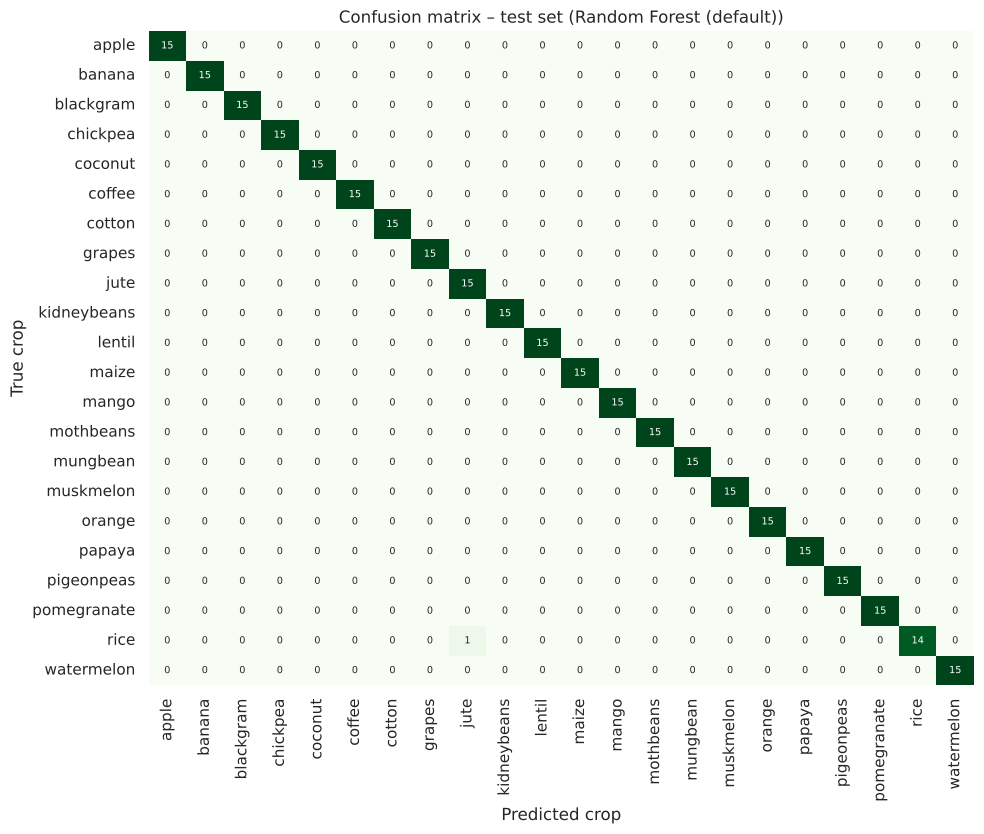

Misclassified test rows: 1 of 330


,N,P,K,temperature,humidity,ph,rainfall,true,predicted,confidence,true_in_top3
45,91,35,38,24.9,80.53,6.13,183.68,rice,jute,0.57,True


Mean confidence – correct predictions: 0.953 | wrong predictions: 0.570


In [17]:
# Confusion matrix (normalised by true class)
labels = list(final.classes_)
cm = confusion_matrix(y_test, pred, labels=labels)
fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=labels, yticklabels=labels,
            cbar=False, annot_kws={"size": 7}, ax=ax)
ax.set(xlabel="Predicted crop", ylabel="True crop", title=f"Confusion matrix – test set ({final_name})")
plt.xticks(rotation=90); plt.tight_layout()
plt.savefig("figures/08_confusion_matrix.png", dpi=150); plt.show()

# Error analysis: every misclassified test row
conf = proba.max(axis=1)
wrong = (pred != y_test.values)
errs = X_test.assign(true=y_test.values, predicted=pred, confidence=conf.round(3)).loc[wrong]
top3 = [list(final.classes_[np.argsort(p)[::-1][:3]]) for p in proba[wrong]]
errs["true_in_top3"] = [t in tt for t, tt in zip(errs["true"], top3)]
print(f"Misclassified test rows: {int(wrong.sum())} of {len(y_test)}")
display(errs.round(2))
print(f"Mean confidence – correct predictions: {conf[~wrong].mean():.3f} | wrong predictions: "
      f"{conf[wrong].mean() if wrong.any() else float('nan'):.3f}")

In [18]:
# How certain is the difference to the baseline? Bootstrap the test set (1,000 resamples)
rng = np.random.default_rng(RS)
base_pred = fitted[baseline_name].predict(X_test)
yt = y_test.values
diffs = []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    diffs.append(f1_score(yt[idx], pred[idx], average="macro") - f1_score(yt[idx], base_pred[idx], average="macro"))
lo_ci, hi_ci = np.percentile(diffs, [2.5, 97.5])
print(f"Macro-F1 gain over baseline: {test_m['macro_f1'] - base_m['macro_f1']:+.4f}  (95% bootstrap CI {lo_ci:+.4f} to {hi_ci:+.4f})")

# Supplementary check (not used for selection): 5-fold CV of the chosen configuration on ALL data
cv_all = cross_val_score(final, X, y, cv=cv5, scoring="f1_macro", n_jobs=-1)
print(f"5-fold CV macro F1 on the full dataset: {cv_all.mean():.4f} ± {cv_all.std():.4f}")

Macro-F1 gain over baseline: +0.0246  (95% bootstrap CI +0.0092 to +0.0452)


5-fold CV macro F1 on the full dataset: 0.9954 ± 0.0032


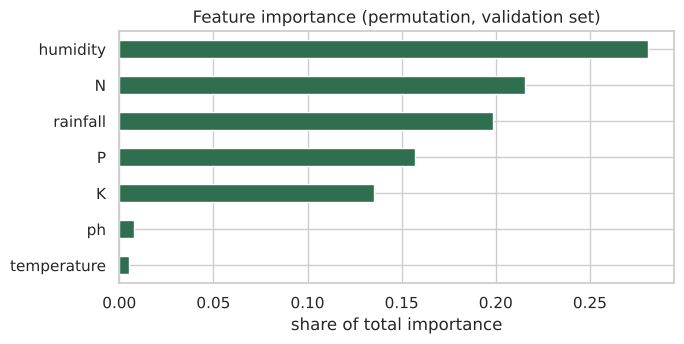

humidity       0.281
N              0.216
rainfall       0.199
P              0.157
K              0.135
ph             0.008
temperature    0.005


In [19]:
# Explainability: which inputs does the final model rely on? (permutation importance on the validation set)
pi = permutation_importance(final, X_val, y_val, scoring="f1_macro", n_repeats=15, random_state=RS, n_jobs=-1)
imp = pd.Series(np.clip(pi.importances_mean, 0, None), index=FEATURES)
imp_norm = (imp / imp.sum()).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 3.6))
imp_norm.sort_values().plot.barh(ax=ax, color="#2f6f4f")
ax.set(title="Feature importance (permutation, validation set)", xlabel="share of total importance")
plt.tight_layout(); plt.savefig("figures/09_feature_importance.png", dpi=150); plt.show()
print(imp_norm.round(3).to_string())

,noise (fraction of feature std),test accuracy
0,0.00,0.9970
1,0.05,0.9858
2,0.10,0.9592
3,0.20,0.8645
4,0.30,0.7424


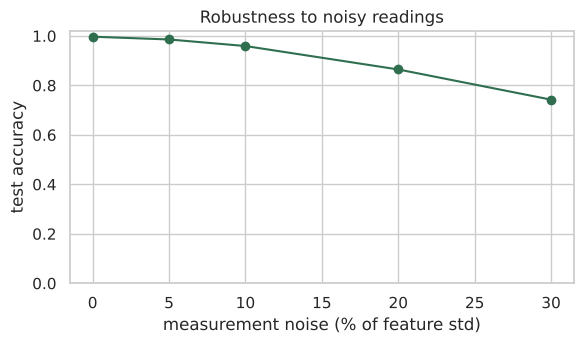

In [20]:
# Robustness: how fast does accuracy fall when inputs are measured with error?
# (adds Gaussian noise equal to a fraction of each feature's standard deviation, then clips to valid limits)
sd_train = X_train.std()
levels, accs = [0, 0.05, 0.10, 0.20, 0.30], []
for s in levels:
    run = []
    for r in range(20):
        rng = np.random.default_rng(RS + r)
        Xn = X_test + rng.normal(0, 1, X_test.shape) * sd_train.values * s
        for f in FEATURES:
            Xn[f] = Xn[f].clip(*HARD_LIMITS[f])
        run.append(accuracy_score(y_test, final.predict(Xn)))
    accs.append(float(np.mean(run)))
noise_df = pd.DataFrame({"noise (fraction of feature std)": levels, "test accuracy": np.round(accs, 4)})
display(noise_df)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot([l * 100 for l in levels], accs, "o-", color="#2f6f4f")
ax.set(xlabel="measurement noise (% of feature std)", ylabel="test accuracy", ylim=(0, 1.02),
       title="Robustness to noisy readings")
plt.tight_layout(); plt.savefig("figures/10_noise_robustness.png", dpi=150); plt.show()

### Save the final model and check it against the success criteria

In [21]:
train_ranges = {f: [float(X_train[f].min()), float(X_train[f].max())] for f in FEATURES}
joblib.dump(final, "models/crop_model.joblib")
meta = {
    "model_name": final_name,
    "baseline_name": baseline_name,
    "classes": [str(c) for c in final.classes_],
    "features": FEATURES,
    "training_ranges": train_ranges,
    "feature_importance": {k: float(v) for k, v in imp_norm.items()},
    "low_confidence_threshold": 0.5,
    "sklearn_version": sklearn.__version__,
    "test_metrics": {k: (float(v) if not isinstance(v, str) else v) for k, v in test_m.items()},
    "baseline_test_metrics": {k: (float(v) if not isinstance(v, str) else v) for k, v in base_m.items()},
}
Path("models/model_meta.json").write_text(json.dumps(meta, indent=2))

# Latency: timed single-record inference through the same code path the app uses
model_loaded, meta_loaded = load_model()
sample = X_test.iloc[0].to_dict()
recommend(sample, model_loaded, meta_loaded)  # warm-up
t0 = time.perf_counter()
for _ in range(200):
    recommend(sample, model_loaded, meta_loaded)
latency_ms = (time.perf_counter() - t0) / 200 * 1000

checks = [
    ("Macro F1 >= 0.90",                    test_m["macro_f1"] >= 0.90,        f"{test_m['macro_f1']:.4f}"),
    ("Accuracy >= 0.90",                    test_m["accuracy"] >= 0.90,        f"{test_m['accuracy']:.4f}"),
    ("No class recall below 0.80",          test_m["min_class_recall"] >= 0.80, f"min {test_m['min_class_recall']:.3f} ({test_m['worst_class']})"),
    ("Top-3 accuracy >= 98%",               test_m["top3_accuracy"] >= 0.98,   f"{test_m['top3_accuracy']:.4f}"),
    ("Beats baseline on macro F1",          test_m["macro_f1"] > base_m["macro_f1"], f"{test_m['macro_f1']-base_m['macro_f1']:+.4f}"),
    ("Latency well under 1 second",         latency_ms < 1000,                 f"{latency_ms:.1f} ms"),
]
crit = pd.DataFrame(checks, columns=["Success criterion (Module 4)", "Met?", "Result"])
crit["Met?"] = crit["Met?"].map({True: "YES", False: "NO"})
display(crit)

Path("outputs/metrics.json").write_text(json.dumps({
    "final_model": final_name, "baseline": baseline_name,
    "validation_table": results.round(4).reset_index(names="model").to_dict(orient="records"),
    "test_final": meta["test_metrics"], "test_baseline": meta["baseline_test_metrics"],
    "bootstrap_gain_ci": [float(lo_ci), float(hi_ci)],
    "cv_full_data": [float(cv_all.mean()), float(cv_all.std())],
    "misclassified": int(wrong.sum()), "n_test": int(len(y_test)),
    "noise_robustness": noise_df.round(4).to_dict(orient="records"),
    "latency_ms": float(latency_ms),
    "feature_importance": meta["feature_importance"],
    "class_separation_F": {k: float(v) for k, v in sep.items()},
    "outliers_removed_vs_kept_val_f1": [float(b), float(a)],
    "train_outlier_rows": int(is_out.sum()),
    "rf_best_params": rf_search.best_params_, "svm_best_params": svm_search.best_params_,
    "use_ratio_features_for_tuning": bool(use_ratios),
    "tied_models": list(tied.index),
}, indent=2, default=str))
print("Saved: models/crop_model.joblib, models/model_meta.json, outputs/metrics.json")

,Success criterion (Module 4),Met?,Result
0,Macro F1 >= 0.90,YES,0.9970
1,Accuracy >= 0.90,YES,0.9970
2,No class recall below 0.80,YES,min 0.933 (rice)
3,Top-3 accuracy >= 98%,YES,1.0000
4,Beats baseline on macro F1,YES,+0.0246
5,Latency well under 1 second,YES,9.9 ms


Saved: models/crop_model.joblib, models/model_meta.json, outputs/metrics.json


### Strengths, limitations and possible errors (read with the numbers above)
- **Strengths:** the model separates the 22 crops very well on this benchmark, returns calibrated-looking top-3 alternatives, answers in milliseconds, and its errors (listed above) are few and concentrated among crops with similar profiles.
- **Limitation 1 – benchmark effect:** the dataset is clean, balanced and highly separable, so near-perfect scores are partly a property of the data. Real farm data is noisier; the noise-robustness curve shows how quickly accuracy falls when readings are imprecise.
- **Limitation 2 – geography:** trained only on conditions represented in this dataset (Indian agronomic data). Recommendations for other climates / soils are unvalidated.
- **Limitation 3 – what the label means:** the label says which crop *typically grows* under such conditions, not which crop is *most profitable* for the farmer. Market prices, irrigation, seed availability and farmer preference are outside the model.
- **Limitation 4 – statistical resolution:** the test set has 330 rows, so differences of one or two predictions between models are not meaningful (see the bootstrap interval).
- **Possible errors:** confusion between agronomically similar crops, and over-confident answers for inputs outside the training ranges – handled in Task 8 with explicit warnings.

---
## Task 8 – Test the Solution
We test the **complete workflow, input → validation → model → output**, by reloading the *saved* model from disk and calling the same `recommend()` function the Streamlit app uses.

In [22]:
model_loaded, meta_loaded = load_model()

# 8.1 Round trip: the saved model must reproduce the in-memory predictions exactly
assert (model_loaded.predict(X_test) == final.predict(X_test)).all()
print("Saved model reproduces the in-memory predictions on all", len(X_test), "test rows.")

def show(title, values, expect_ok=True, expect_warning=None):
    out = recommend(values, model_loaded, meta_loaded)
    top = ", ".join(f"{t['crop']} ({t['confidence']:.0%})" for t in out["top"]) or "-"
    ok_match = out["ok"] == expect_ok
    warn_match = True if expect_warning is None else (bool(out["warnings"]) == expect_warning)
    status = "PASS" if (ok_match and warn_match) else "FAIL"
    return {"case": title, "result": top if out["ok"] else "REJECTED: " + out["errors"][0],
            "warnings": len(out["warnings"]), "expected": "accepted" if expect_ok else "rejected", "status": status}

rows = []

Saved model reproduces the in-memory predictions on all 330 test rows.


### 8.2 Realistic cases – typical profile of several crops, plus unseen test rows

In [23]:
# Typical (median) readings of five very different crops from the training data -> should be recommended first
for crop in ["rice", "maize", "chickpea", "apple", "coffee"]:
    vals = X_train[y_train == crop].median().to_dict()
    r = show(f"Typical {crop}", vals)
    out = recommend(vals, model_loaded, meta_loaded)
    r["status"] = "PASS" if out["top"][0]["crop"] == crop else "FAIL"
    rows.append(r)

# Five random unseen test rows: top-1 and top-3 correct?
for i in np.random.default_rng(RS).choice(len(X_test), 5, replace=False):
    vals, truth = X_test.iloc[i].to_dict(), y_test.iloc[i]
    out = recommend(vals, model_loaded, meta_loaded)
    r = show(f"Unseen test row (true: {truth})", vals)
    r["status"] = "PASS" if truth in [t["crop"] for t in out["top"]] else "FAIL"
    rows.append(r)
display(pd.DataFrame(rows))

,case,result,warnings,expected,status
0,Typical rice,"rice (94%), jute (6%), pomegranate (0%)",0,accepted,PASS
1,Typical maize,"maize (100%), watermelon (0%), pomegranate (0%)",0,accepted,PASS
2,Typical chickpea,"chickpea (100%), watermelon (0%), pomegranate ...",0,accepted,PASS
3,Typical apple,"apple (100%), watermelon (0%), pomegranate (0%)",0,accepted,PASS
4,Typical coffee,"coffee (99%), maize (1%), pomegranate (0%)",0,accepted,PASS
5,Unseen test row (true: mango),"mango (100%), watermelon (0%), pomegranate (0%)",0,accepted,PASS
6,Unseen test row (true: mothbeans),"mothbeans (98%), mungbean (2%), pomegranate (0%)",0,accepted,PASS
7,Unseen test row (true: orange),"orange (99%), pomegranate (1%), rice (0%)",0,accepted,PASS
8,Unseen test row (true: rice),"rice (95%), jute (3%), coconut (1%)",0,accepted,PASS
9,Unseen test row (true: mungbean),"mungbean (100%), watermelon (0%), pomegranate ...",0,accepted,PASS


### 8.3 Edge cases – boundary, extreme, missing and invalid inputs

In [24]:
base_vals = X_test.iloc[0].to_dict()
def variant(**kw):
    v = dict(base_vals); v.update(kw); return v

edge = []
edge.append(show("All nutrients zero (N=P=K=0 is physically valid)", variant(N=0, P=0, K=0), True))
edge.append(show("Maximum values seen in training", {f: float(X_train[f].max()) for f in FEATURES}, True))
edge.append(show("Minimum values seen in training", {f: float(X_train[f].min()) for f in FEATURES}, True))
edge.append(show("pH = 14 (valid but far outside training range)", variant(ph=14), True, expect_warning=True))
edge.append(show("pH = 0.5 (valid but far outside training range)", variant(ph=0.5), True, expect_warning=True))
edge.append(show("Very dry plot, rainfall = 5 mm (outside training range)", variant(rainfall=5), True, expect_warning=True))
edge.append(show("Illustrative cool-highland profile (not from the dataset)",
                 dict(N=60, P=40, K=40, temperature=12, humidity=60, ph=6.2, rainfall=110), True))
edge.append(show("Numbers supplied as text ('50')", variant(N="50", P="40"), True))
edge.append(show("Humidity 120 % (impossible)", variant(humidity=120), False))
edge.append(show("Negative rainfall", variant(rainfall=-10), False))
edge.append(show("Negative nitrogen", variant(N=-1), False))
edge.append(show("pH 15 (impossible)", variant(ph=15), False))
edge.append(show("Missing value (no pH)", {k: v for k, v in base_vals.items() if k != "ph"}, False))
edge.append(show("Non-numeric input ('abc')", variant(K="abc"), False))
edge.append(show("NaN input", variant(N=float("nan")), False))
edge.append(show("Empty string input", variant(temperature=""), False))
edge.append(show("Infinite input", variant(rainfall=float("inf")), False))

edge_df = pd.DataFrame(edge)
display(edge_df)
all_cases = pd.concat([pd.DataFrame(rows), edge_df], ignore_index=True)
all_cases.to_csv("outputs/test_cases.csv", index=False)
n_pass = int((all_cases["status"] == "PASS").sum())
print(f"\nTEST SUMMARY: {n_pass} of {len(all_cases)} cases passed")
assert n_pass == len(all_cases), "Some test cases failed - inspect the table above"

,case,result,warnings,expected,status
0,All nutrients zero (N=P=K=0 is physically valid),"orange (31%), pigeonpeas (19%), mothbeans (15%)",3,accepted,PASS
1,Maximum values seen in training,"apple (45%), banana (29%), papaya (12%)",1,accepted,PASS
2,Minimum values seen in training,"kidneybeans (38%), muskmelon (30%), orange (10%)",1,accepted,PASS
3,pH = 14 (valid but far outside training range),"coffee (98%), watermelon (1%), jute (1%)",1,accepted,PASS
4,pH = 0.5 (valid but far outside training range),"coffee (89%), mango (3%), rice (2%)",1,accepted,PASS
5,"Very dry plot, rainfall = 5 mm (outside traini...","muskmelon (49%), coffee (18%), maize (13%)",2,accepted,PASS
6,Illustrative cool-highland profile (not from t...,"maize (35%), coffee (22%), jute (20%)",1,accepted,PASS
7,Numbers supplied as text ('50'),"mango (30%), pigeonpeas (27%), coffee (15%)",1,accepted,PASS
8,Humidity 120 % (impossible),REJECTED: 'humidity'=120.0 is outside the vali...,0,rejected,PASS
9,Negative rainfall,REJECTED: 'rainfall'=-10.0 is outside the vali...,0,rejected,PASS



TEST SUMMARY: 27 of 27 cases passed


### 8.4 Findings from testing
- Valid inputs return a ranked top-3 list with confidences; invalid input (missing, non-numeric, NaN/infinite, impossible values such as humidity above 100 % or pH above 14) is **rejected with a clear message** instead of producing a misleading crop.
- Valid-but-unusual input (e.g. pH 14 or rainfall far below anything in the training data) is **accepted but flagged** with an out-of-range warning, because a tree/SVM model will always produce *some* answer even where it has no evidence.
- A low-confidence warning is added when the top probability is below 0.5, nudging users to look at the alternatives and consult an extension officer.

**Working prototype:** run `streamlit run app.py` – a form for the seven readings that calls the same `recommend()` function tested here (see `README.md`).